# Setup
## Dependencies

In [65]:
%config InlineBackend.figure_format = 'retina'
import sqlite3
from pathlib import Path
from datetime import date
import matplotlib.pyplot as plt
import math

## File Paths

In [66]:
db_path = Path("../databases/Master_Database.db").resolve()
conn = sqlite3.connect(db_path)

In [67]:
band_colors = {
    "B": "tab:blue",
    "V": "tab:green",
    "R": "tab:red",
    "r": "tab:orange",
    "I": "tab:purple",
}
band_order = ["B", "V", "R", "r", "I"]

## Dictionaries

In [68]:
discovered_date = {
    "aepk": ("2026-10-06"),
    "abxl": ("2026-09-16"),
    "acna": ("2026-09-20"),
    "aaiv": ("2026-09-01"),
    "aeiv": ("2026-10-05"),
    "aesj": ("2026-10-07"),
    "afsg": ("2026-10-18"),
    "acpp": ("2026-09-21"),
}

# Functions

In [69]:
def get_supernova(sn_name, conn):
    sql = """
        SELECT obs_date, filter, mag, mag_err
        FROM observations
        WHERE object LIKE ?
            AND mag IS NOT NULL
        ORDER BY obs_date
    """

    #short_sn_name = sn_name[-4:].lower()
    #output = conn.execute(sql, (short_sn_name,))

    full_name = "%"+sn_name      
    output = conn.execute(sql, (full_name,)).fetchall()

    return (output)

In [70]:
def get_bands(sn_name, data_list):
    bands_list = {}

    discovery_date = date.fromisoformat(discovered_date[sn_name])
    

    for obs_date, band, mag, mag_err in data_list:
        date_dif = (date.fromisoformat(obs_date)-discovery_date).days

        if mag_err is None:
            mag_err = math.nan

        if band not in bands_list:
            bands_list[band] = {"days": [], "mags": [], "mag_errs": []}

        bands_list[band]["days"].append(date_dif)
        bands_list[band]["mags"].append(mag)
        bands_list[band]["mag_errs"].append(mag_err)

    return bands_list

In [71]:
data_list = get_supernova("aaiv", conn)
print(get_bands("aaiv", data_list))


{'R': {'days': [23, 30, 31, 32, 35, 36, 38, 39, 40, 41, 42], 'mags': [12.552732474367673, 12.908840058440175, 12.929024718706637, 12.893604497765379, 13.01545797902206, 13.030902089778102, 13.161609393120438, 13.337580036564706, 13.29228473575313, 13.389238203151233, 13.396000607291082], 'mag_errs': [nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan]}, 'V': {'days': [30, 31, 32, 35, 36, 38, 39, 39, 40, 41, 42], 'mags': [13.016434050017986, 13.0632819349119, 13.058511974533928, 13.295612961191225, 13.350835199548815, 13.576796829961806, 13.514788606993212, 13.574656047280497, 13.705917842853662, 13.770603467845476, 13.825750335224921], 'mag_errs': [nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan]}, 'I': {'days': [30, 31, 32, 35, 36, 38, 39, 40, 41, 42], 'mags': [12.918205530985603, 12.922013959574256, 12.943638993468824, 12.850561152266009, 12.805543622252632, 12.882782700429475, 12.852637110426087, 12.891906959144608, 13.022483323883668, 12.995489690924952], 'mag_errs': [nan,

In [86]:
def plot_figure(sn_name, bands, output_folder):
    
    fig, ax = plt.subplots(figsize=(8, 5))

    for band in band_order:
        if band not in bands:
            continue

        points = bands[band]
        point_color = band_colors[band]

        #ax.plot(points["days"], points["mags"], "o-", color=point_color, label=band)
        ax.errorbar(points["days"], points["mags"], points["mag_errs"], fmt='o', mfc = 'white', 
                    markersize=5, elinewidth=1, capsize = 3, color=point_color, label = band)

    ax.invert_yaxis()
    ax.set_xlabel("Days Since Discovery")
    ax.set_ylabel("Apparent Magnitude")
    ax.set_ylim(18, 10)
    ax.set_title(f"SN 2026{sn_name.upper()} light curve")
    ax.legend(title="Band")
    

    output_folder.mkdir(parents=True, exist_ok=True)
    output_file = output_folder / f"{sn_name}_light_curve.png"
    fig.savefig(output_file, dpi=200, bbox_inches="tight")

    plt.show()

    return #output_file




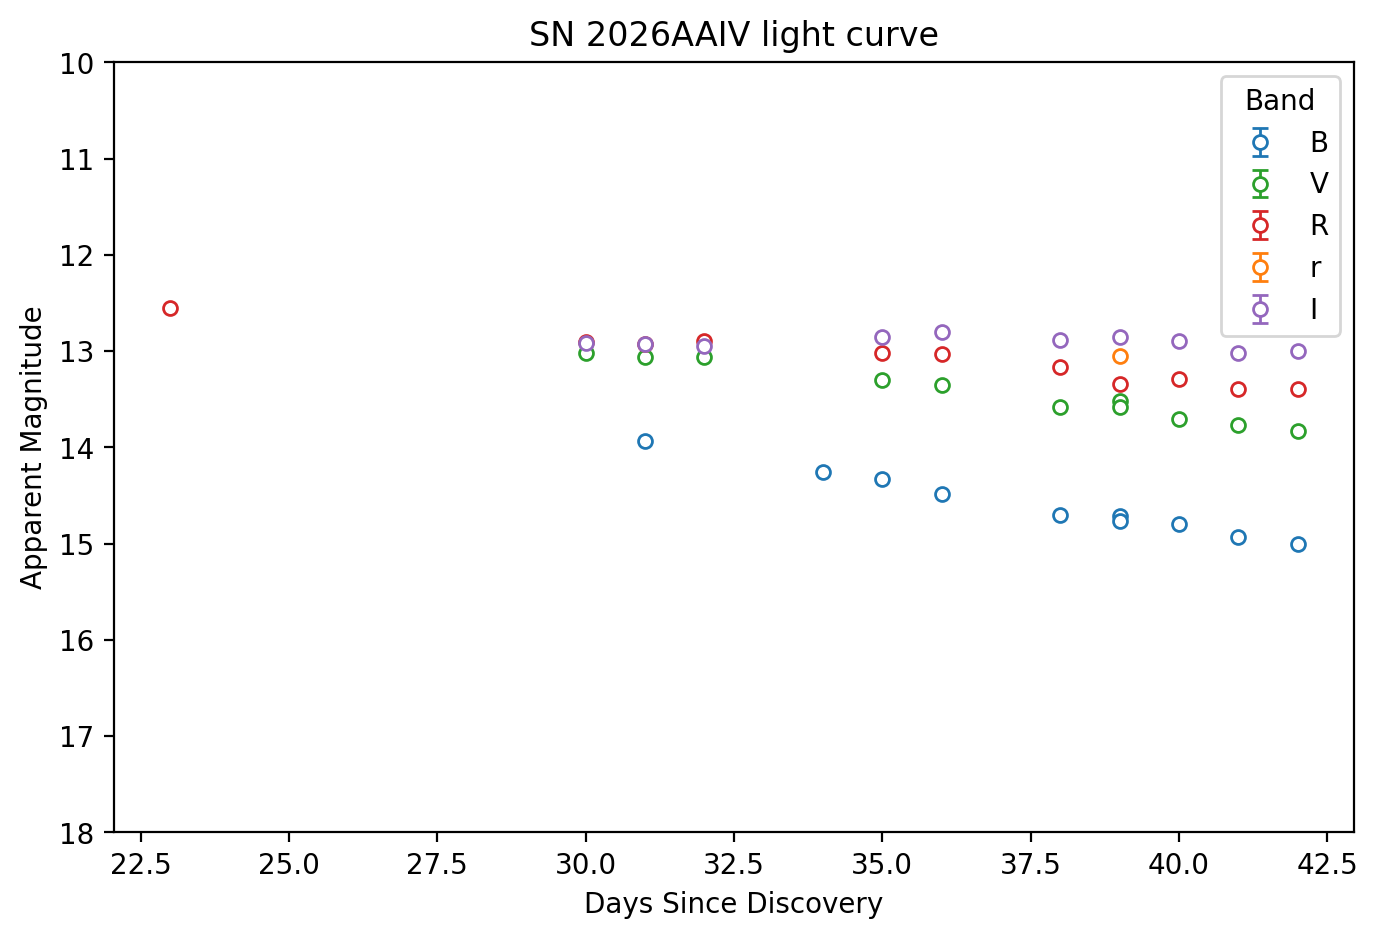

/var/folders/8m/x8f071113t3d7gdwzp03c1f40000gn/T/ipykernel_93057/797873825.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title="Band")


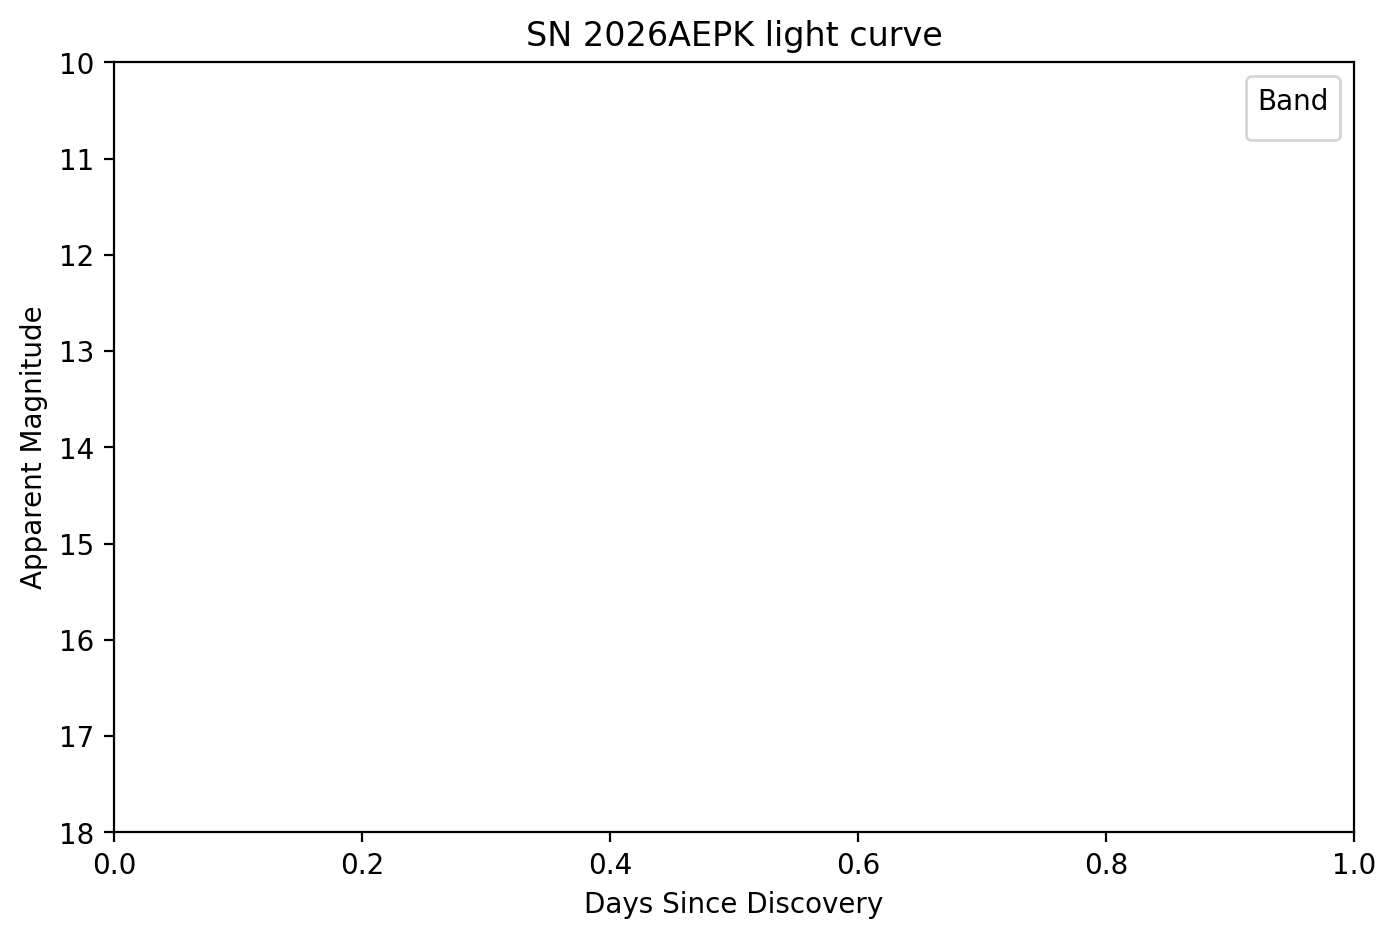

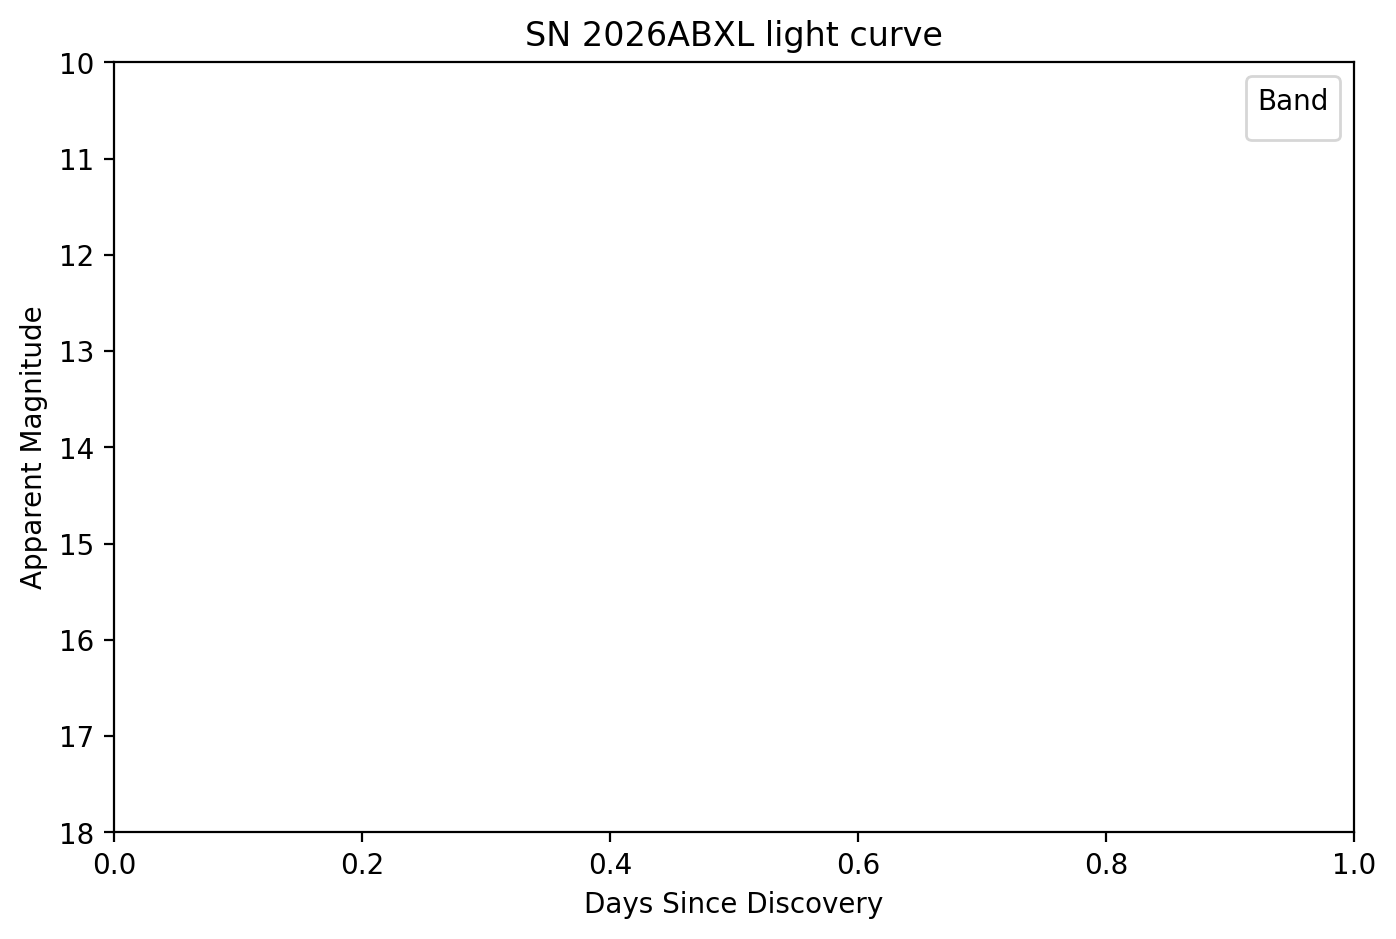

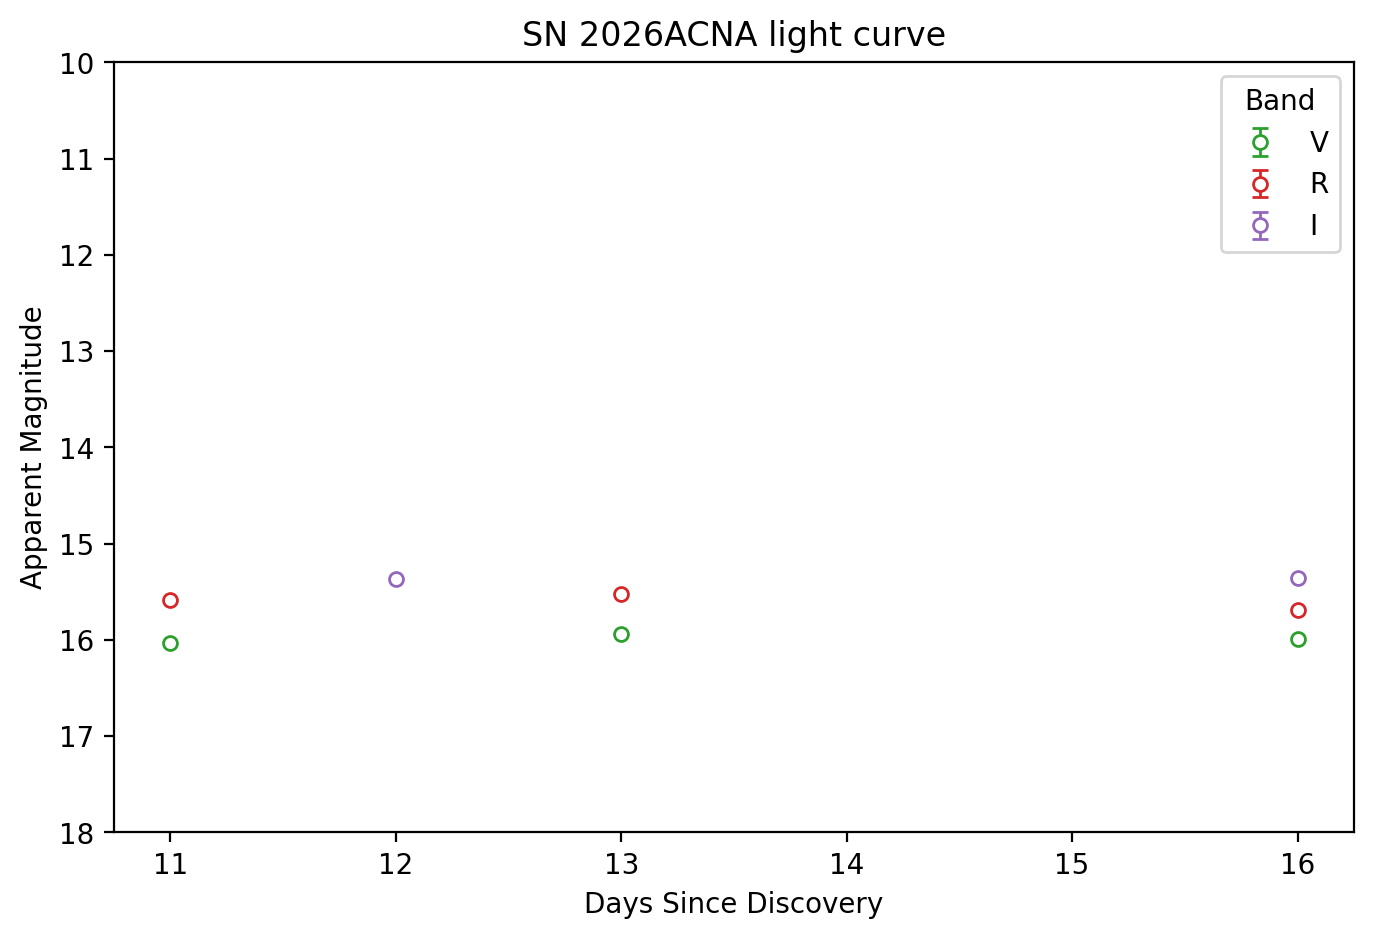

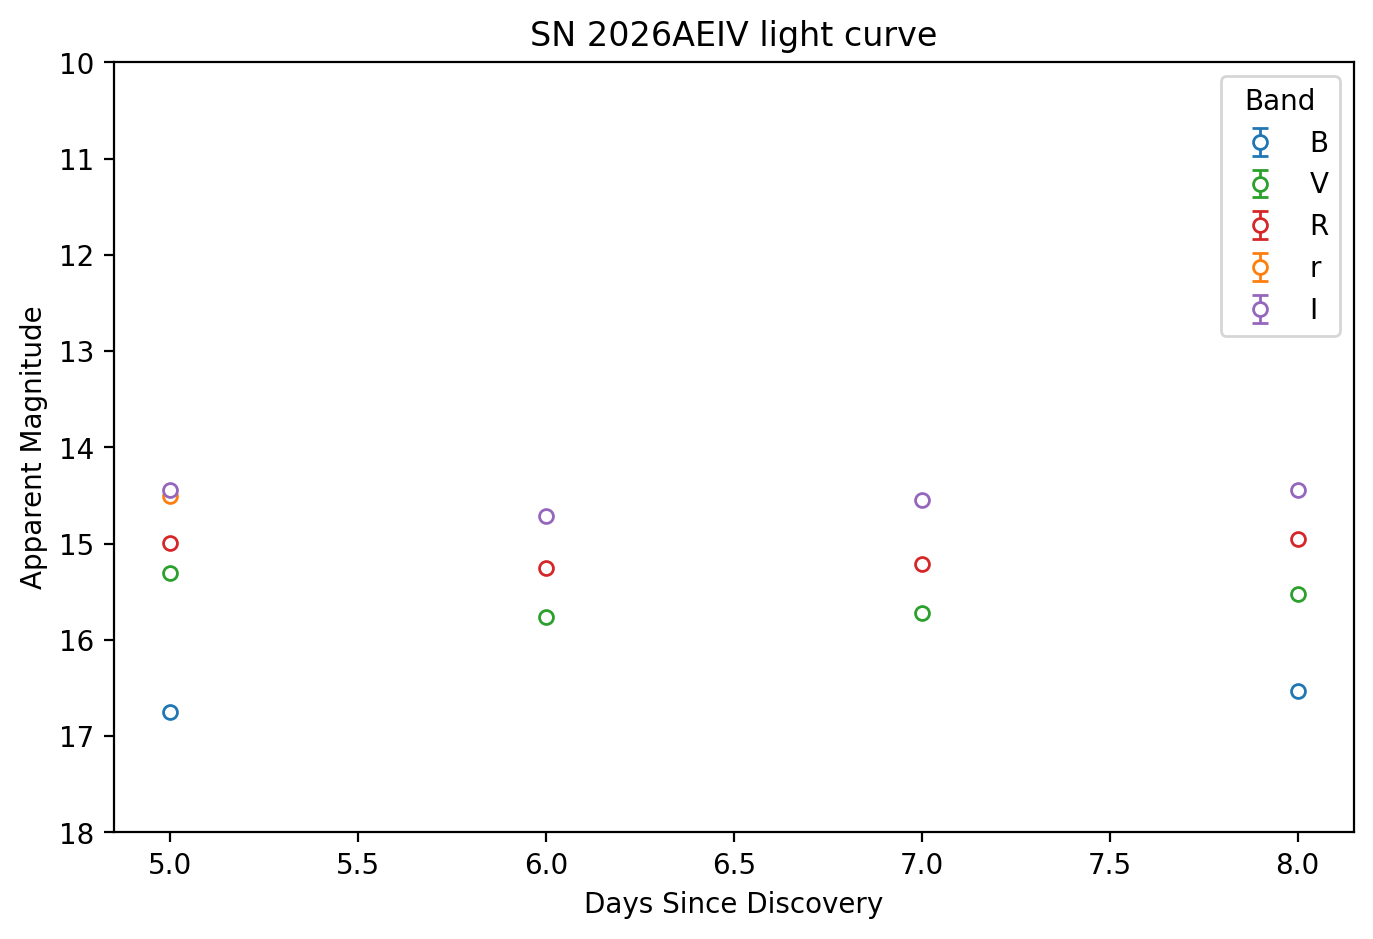

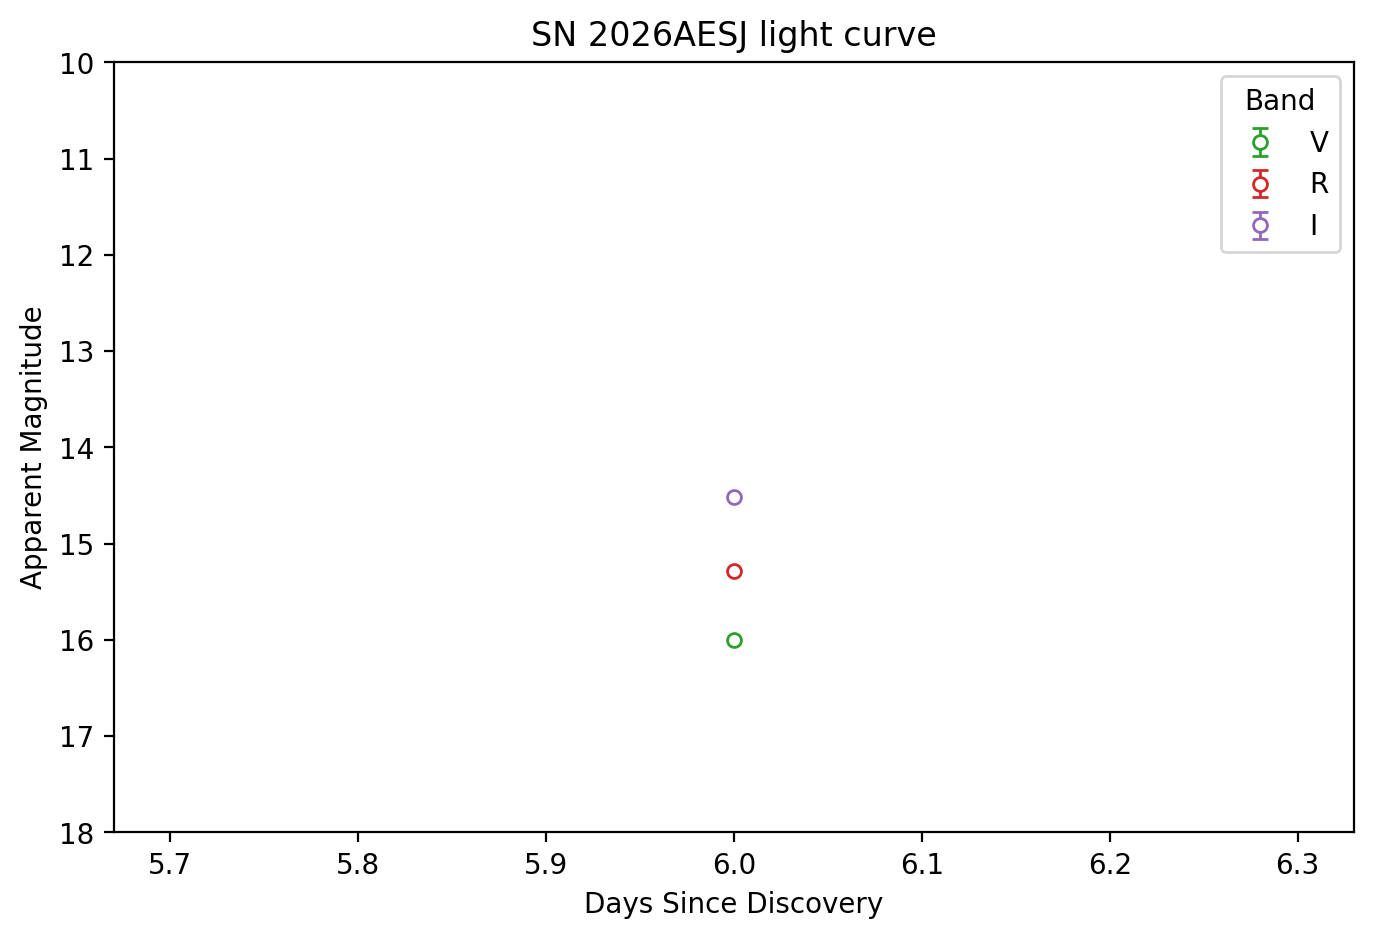

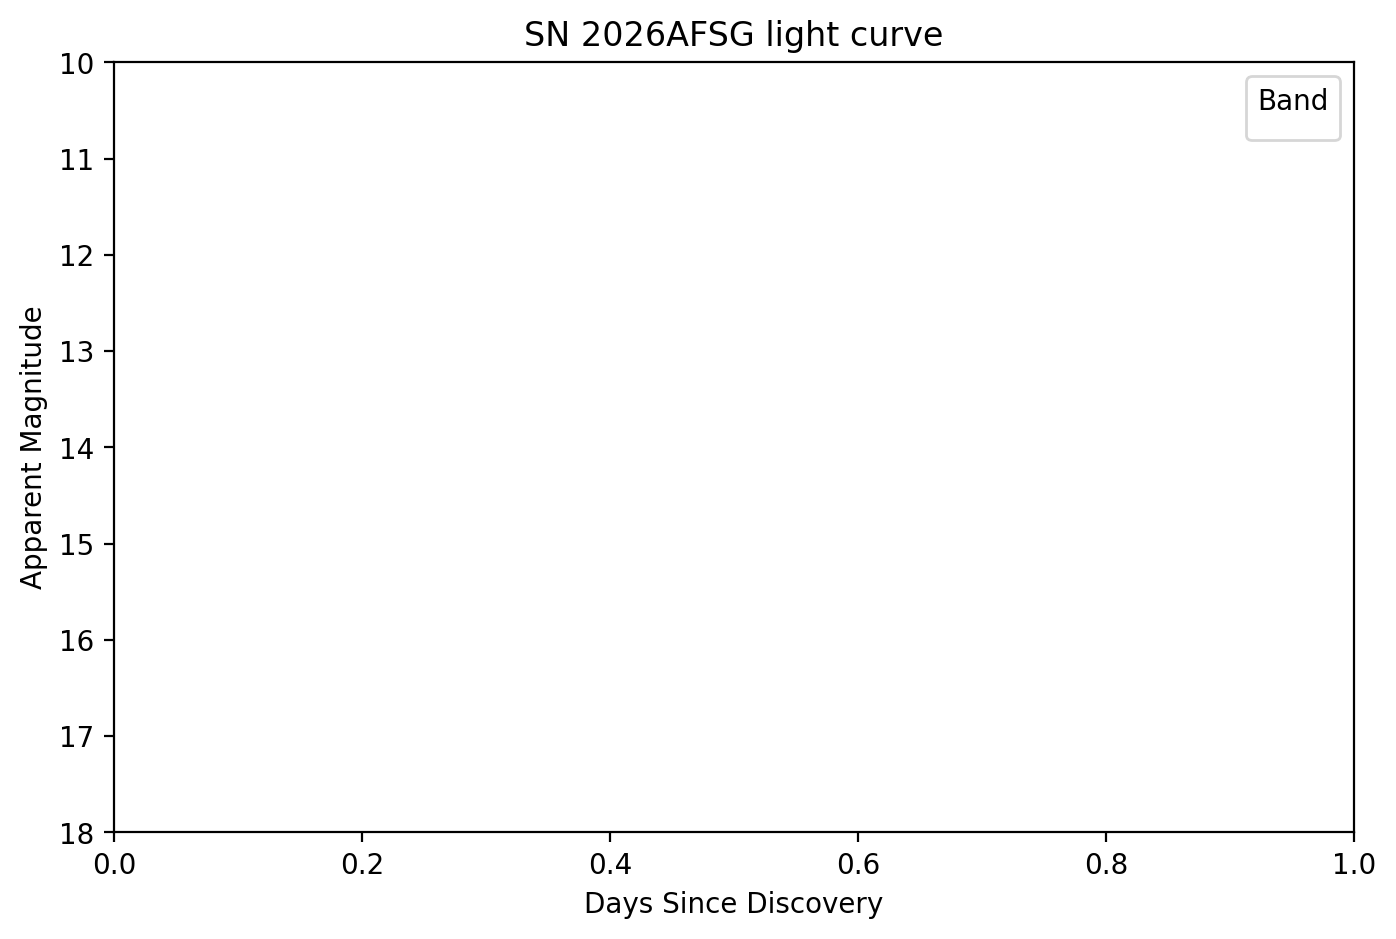

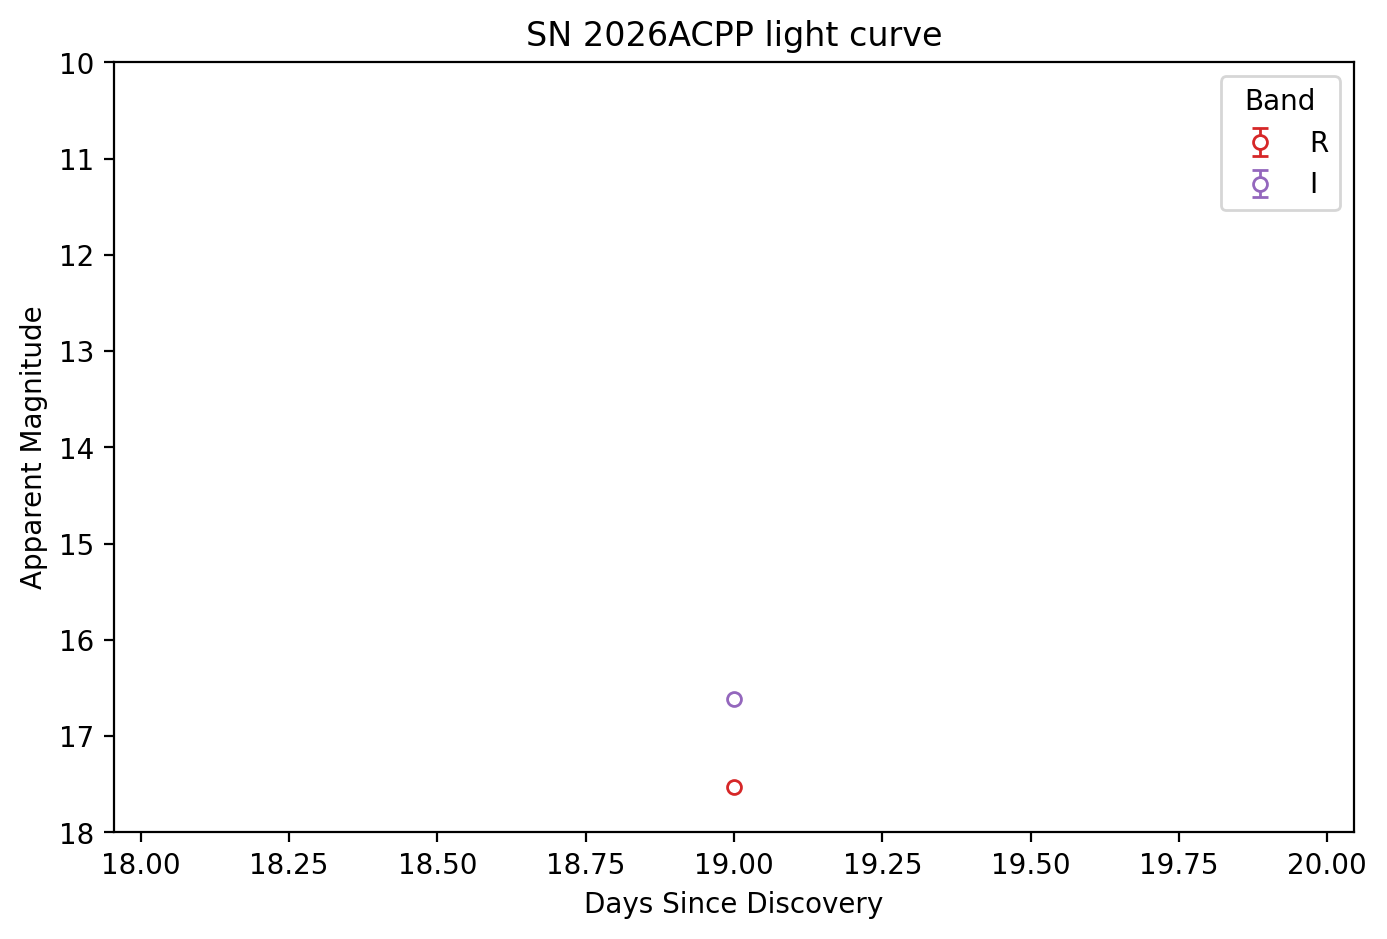

In [87]:
sn_list = ("aaiv",
           "aepk", "abxl", "acna",  "aeiv", "aesj", "afsg", "acpp"
          )

for sn in sn_list:
    data_list = get_supernova(sn, conn)
    bands = get_bands(sn, data_list)

    plot_figure(sn, bands, Path("../output light curves"))

In [59]:
for sn_name in discovered_date:
    data_list = get_supernova(sn_name, conn)

    nights = []
    for obs_date, band, mag, mag_err in data_list:
        if obs_date not in nights:
            nights.append(obs_date)

    print(sn_name,":", len(nights), "nights,", len(data_list), "magnitudes")

aepk : 0 nights, 0 magnitudes
abxl : 0 nights, 0 magnitudes
acna : 4 nights, 8 magnitudes
aaiv : 12 nights, 43 magnitudes
aeiv : 4 nights, 15 magnitudes
aesj : 1 nights, 3 magnitudes
afsg : 0 nights, 0 magnitudes
acpp : 1 nights, 2 magnitudes
